# Лекція 4. Трансформери та мовні моделі.

In [1]:
%pip install -q "transformers>=4.51,<5" datasets tokenizers sentencepiece tensorboard evaluate gradio accelerate scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


Адаптація для Colab: 3000 віршів, 500 ітерацій, менша модель Qwen3-0.6B. Це скорочений демонстраційний прогін, не оригінальні 8000 ітерацій.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [2]:
import sys
import os
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

### 0.1. Перевіряємо чи ми точно в Colab

In [3]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)



Running in Colab: True


### 0.2. Використовуємо графічний прискорювач, якщо доступний.
На Colab зазвичай є безкоштовний GPU (T4).
Використовуємо його, якщо він доступний.
Якщо ні, залишаємося на CPU.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cpu


### 0.3. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінти mini-GPT й логи TensorBoard пережили
перезапуск.

In [5]:
ARTIFACT_DIR = "/content/demo_artifacts" if IN_COLAB else "demo_artifacts"
RUNS_DIR = os.path.join(ARTIFACT_DIR,"runs")
os.makedirs(RUNS_DIR,exist_ok=True)

---
## 1. Корпус: українська поезія

Для mini-GPT з нуля потрібен текстовий корпус однією мовою, достатньо
великий, щоб модель могла вивчити бодай прості закономірності.

Використовуємо датасет [`RudyiVT/ukrainian-poems`](https://huggingface.co/datasets/RudyiVT/ukrainian-poems)
(17 918 віршів, 757 авторів, зібрано з [ukrlib.com.ua](https://www.ukrlib.com.ua/))
повністю — весь текст іде в один суцільний корпус для тренування.

### 1.1. Завантажуємо датасет з Hugging Face Hub

In [6]:
from datasets import load_dataset

poems_dataset = load_dataset("RudyiVT/ukrainian-poems", split="train[:3000]")
print("Усього віршів у датасеті:", len(poems_dataset))
print("Колонки:", poems_dataset.column_names)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…):   0%|          | 0.00/58.6M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

Усього віршів у датасеті: 3000
Колонки: ['author', 'author_url', 'poem_name', 'poem_url', 'context_author', 'context_poem_name', 'context_poem']


### 1.2. Збираємо суцільний корпус

In [7]:
poems_df = poems_dataset.to_pandas()
corpus_text = "\n\n".join(poems_df["context_poem"].dropna().tolist())

print("Розмір корпусу:", len(corpus_text), "символів")
print("Перші 500 символів корпусу:\n", corpus_text[:500])

Розмір корпусу: 11176574 символів
Перші 500 символів корпусу:
 У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


### 1.3. Базова статистика корпусу

In [8]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])


Слів (з повторами):    1805974
Унікальних слів:       315193
Приклад уривку:

У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


---
## 2. Токенізація: BPE на власному корпусі

Токенізація перетворює текст на послідовність id. Використовуємо BPE (Byte Pair Encoding),
який досить часто використовується на великих LLM. Тренуємо через `tokenizers` (від HuggingFace)—
переписувати цикл злиття пар вручну немає сенсу: це вже готовий, швидкий (Rust) алгоритм,
а не нова концепція, яку ми тут вивчаємо.

### 2.1. Тренуємо BPE

Тренер бачить датасет як список окремих віршів (а не один суцільний
рядок) — це і природніший спосіб виклику `train_from_iterator`, і легший
для пам'яті: не потрібно тримати весь корпус як один текстовий блок під
час підрахунку частот пар.

In [9]:
VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
poems_iterator = poems_df["context_poem"].dropna().tolist()
bpe_tokenizer.train_from_iterator(poems_iterator, trainer=bpe_trainer)
del poems_iterator

bpe_vocab = bpe_tokenizer.get_vocab()
itos = [None] * len(bpe_vocab)
for tok, idx in bpe_vocab.items():
    itos[idx] = tok
stoi = bpe_vocab
UNK_ID = stoi["<unk>"]

def tokenize(text: str) -> list[str]:
    return bpe_tokenizer.encode(text).tokens

def encode(tokens: list[str]) -> list[int]:
    return [stoi.get(t, UNK_ID) for t in tokens]

def decode(ids: list[int]) -> str:
    return bpe_tokenizer.decode(ids)

print("Розмір словника (BPE):", len(itos))

Розмір словника (BPE): 16000


### 2.2. Кодуємо корпус у послідовність id

Кодуємо пачками (`.encode_batch()`) по кілька сотень віршів, одразу перетворюючи кожен
результат на компактний `numpy` масив (`int32`, 4 байти на токен). Один
виклик `encode()` на весь корпус одразу тримає у пам'яті і список токенів,
і список id для всього тексту разом, що може призвести до вичерпання памʼяті (out of memory, OOM).

In [10]:
import gc
import numpy as np

ENCODE_BATCH_SIZE = 1000
EOS_ID = stoi["<eos>"]
poems_list = poems_df["context_poem"].dropna().tolist()

token_id_chunks = []
for start in range(0, len(poems_list), ENCODE_BATCH_SIZE):
    batch = poems_list[start:start + ENCODE_BATCH_SIZE]
    encodings = bpe_tokenizer.encode_batch(batch)
    for enc in encodings:
        # <eos> позначає межу між віршами — без цього при конкатенації
        # останній токен одного вірша впритул стикається з першим токеном
        # наступного, і модель бачить один суцільний текст замість окремих творів.
        token_id_chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
    del encodings
del poems_list
gc.collect()

token_ids = np.concatenate(token_id_chunks)
del token_id_chunks
gc.collect()

unk_share = (token_ids == UNK_ID).mean()
print(f"Токенів у корпусі (обраний токенізатор): {len(token_ids)}")
print(f"Токенів поза словником (<unk>): {unk_share:.1%}")

data = torch.from_numpy(token_ids.astype(np.int64))
del token_ids
gc.collect()
print("Форма закодованого корпусу:", data.shape)

Токенів у корпусі (обраний токенізатор): 3335018
Токенів поза словником (<unk>): 0.0%
Форма закодованого корпусу: torch.Size([3335018])


### 2.3. Спліт train/val

Для тексту спліт робимо **послідовним** зрізом, а не випадковим
перемішуванням рядків — модель тренується передбачати "наступне слово",
тому послідовність токенів має лишатись цілою.

In [11]:
split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape, " val:", val_data.shape)


train: torch.Size([3001516])  val: torch.Size([333502])


---
## 3. Mini-GPT з нуля

Реалізуємо decoder-only трансформер "з нуля" — так, як на слайдах лекції:
Query/Key/Value власноруч, без `nn.MultiheadAttention` як чорної скриньки.

Модель навмисно маленька: мета — побачити механіку і криву навчання,
а не отримати практично корисний генератор тексту. Тренування вкладається
у 1.5-2 години на безкоштовному Colab T4.

### 3.1. Гіперпараметри

In [12]:
CONTEXT_LEN = 64        # скільки попередніх токенів бачить модель
EMBED_DIM = 128         # розмірність embedding
N_HEADS = 4             # кількість attention-голів
N_LAYERS = 4            # кількість блоків трансформера
DROPOUT = 0.1           # рівень dropout для регуляризації
BATCH_SIZE = 16         # розмір батчу
LEARNING_RATE = 3e-4    # швидкість навчання
MAX_ITERS = 500        # кількість ітерацій навчання
EVAL_INTERVAL = 50     # інтервал (в ітераціях) для оцінки моделі на валідаційній вибірці
EVAL_ITERS = 8         # кількість ітерацій для оцінки на валідаційній вибірці

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS


### 3.2. Батчі: випадкові вікна контексту

Кожен приклад — випадковий зріз довжини `CONTEXT_LEN` з корпусу; таргет —
той самий зріз, зсунутий на один токен вперед (передбачаємо наступне слово
для кожної позиції одночасно).

In [13]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Форма батчу x:", xb.shape, " y:", yb.shape)
assert torch.equal(xb[:,1:],yb[:,:-1])

Форма батчу x: torch.Size([16, 64])  y: torch.Size([16, 64])


### 3.3. Одна attention-голова

Наведемо формулу attention:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

До неї додаємо **причинну маску** (`causal mask`), адже токен на позиції `t` не має права
"дивитися" на токени після себе, інакше модель підглядає відповідь.

In [14]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        # Причинна маска: нижньотрикутна матриця одиниць. register_buffer,
        # а не звичайний атрибут — щоб .to(device) переносив її разом з моделлю.
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)


### 3.4. Multi-head attention

Кілька голів паралельно — кожна вчиться відстежувати інший тип зв'язку між
словами (лекція, розділ "Multi-head attention"). Результати склеюємо
(concat) і пропускаємо ще через один лінійний шар.

In [15]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


### 3.5. Блок трансформера

Multi-head attention + feed-forward, кожен обгорнутий у residual-зв'язок
і layer normalization — ті самі інструменти стабілізації тренування, що
й у лекції 3, застосовані до нового типу шару.

In [16]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)




class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


### 3.6. Повна модель

Токен-embedding + позиційний embedding (лекція, розділ "Позиційне
кодування") → `N_LAYERS` блоків → фінальний лінійний шар, що повертає
розподіл ймовірностей по всьому словнику для кожної позиції.

In [17]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature   # лише останню позицію

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


### 3.7. Ініціалізація моделі

In [18]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")


Кількість параметрів: 4,912,000


### 3.8. Тренування

Той самий цикл, що й у попередніх лекціях: forward → loss → backward →
update, лише loss тепер — cross-entropy передбачення наступного токена.
Оцінюємо val loss періодично (`EVAL_INTERVAL`), а не щоразу — оцінка на
`EVAL_ITERS` батчах дешевша й достатньо точна.

In [19]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "mini_gpt"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        # На диск пишемо лише 2 файли, не по чекпоінту на кожен EVAL_INTERVAL:
        # "перший" — бейзлайн майже випадкової ініціалізації (для порівняння в 3.10),
        # і "найкращий" — перезаписується щоразу, як з'являється новий мінімум val_loss.
        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")
assert torch.equal(xb[:,1:],yb[:,:-1])

iter     0  train_loss=9.798  val_loss=9.805  (0.1 хв)
iter    50  train_loss=8.057  val_loss=8.078  (0.9 хв)
iter   100  train_loss=7.615  val_loss=7.573  (1.5 хв)
iter   150  train_loss=7.458  val_loss=7.585  (2.2 хв)
iter   200  train_loss=7.426  val_loss=7.485  (2.8 хв)
iter   250  train_loss=7.441  val_loss=7.411  (3.5 хв)
iter   300  train_loss=7.254  val_loss=7.332  (4.1 хв)
iter   350  train_loss=7.299  val_loss=7.315  (4.8 хв)
iter   400  train_loss=7.312  val_loss=7.346  (5.4 хв)
iter   450  train_loss=7.287  val_loss=7.277  (6.1 хв)
iter   499  train_loss=7.329  val_loss=7.205  (6.7 хв)

Тренування завершено за 6.7 хв
Найкращий чекпоінт: iter 499  (val_loss=7.205)


### 3.9. Крива навчання

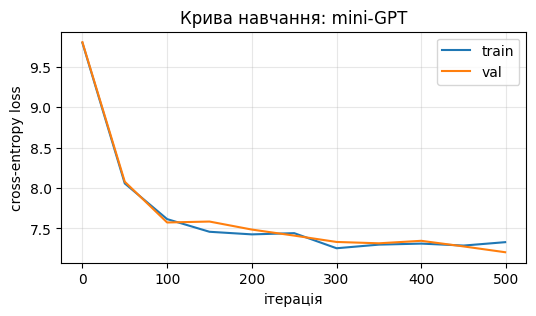

In [20]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


### 3.10. Генерація на різних стадіях тренування

Порівнюємо якість тексту на першому збереженому чекпоінті (майже випадкова
ініціалізація) і на найкращому за val_loss (не обов'язково останньому —
модель могла почати переучуватись ближче до кінця тренування) — той самий
промпт в обох випадках.

In [21]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 40,
                   temperature: float = 0.8, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(tokenize(prompt))], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Реве та стогне"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Реве та стогне Чоловік Щно проходить дверима Думаю звичкою голодні зникаєбно Нез родиніотоміру мн заспокої пляшку загрожлетів змії тими падав крамниціриз слухаєажу базару
 розчарАндрій ножючись високий дровааніт скажіморастуйте підій щоби ров

=== Найкращий чекпоінт (iter 499, val_loss=7.205) ===
Реве та стогне, з від, ще у з.

—
— А, і не до до —

С, —
— Але на не ви,

— А

—


---
## 4. Sampling playground: готова модель

Власна mini-GPT замала, щоб переконливо демонструвати ефект temperature/
top-p — для цього візьмемо малу, але вже по-справжньому навчену відкриту
модель.

### 4.1. Завантажуємо готову модель

In [22]:
del model, optimizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen3-0.6B"

hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype="auto").to(device)
hf_model.eval()

print("Модель завантажено:", MODEL_ID)
print("Параметрів:", sum(p.numel() for p in hf_model.parameters()) / 1e6, "млн")


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель завантажено: Qwen/Qwen3-0.6B
Параметрів: 596.04992 млн


### 4.2. Той самий промпт, різна температура/top-p

Українська — не одна з офіційно заявлених мов цієї моделі, тому якість
може "плавати" — головне тут не ідеальність тексту, а те, як параметри
sampling міняють його характер.

In [23]:
def hf_generate(prompt: str, temperature: float, top_p: float, max_new_tokens: int = 100) -> str:
    messages = [{"role": "user", "content": prompt}]
    text = hf_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    inputs = hf_tokenizer([text], return_tensors="pt").to(device)

    outputs = hf_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
    )
    return hf_tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)


PLAYGROUND_PROMPT = "Продовж речення: Якось уночі студент " \
"Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка"

for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    print(f"--- temperature={temperature}, top_p={top_p} ---")
    print(hf_generate(PLAYGROUND_PROMPT, temperature, top_p))
    print()
print("Thinking enabled:")
text = hf_tokenizer.apply_chat_template([{"role":"user","content":PLAYGROUND_PROMPT}], tokenize=False, add_generation_prompt=True, enable_thinking=True)
inputs=hf_tokenizer([text],return_tensors="pt").to(device)
with torch.no_grad(): out=hf_model.generate(**inputs,max_new_tokens=100,do_sample=True,temperature=0.8,top_p=0.6)
print(hf_tokenizer.decode(out[0][inputs.input_ids.shape[-1]:],skip_special_tokens=True))

--- temperature=0.2, top_p=0.1 ---
підійшов до ліжка, він зіткався з ліжкою, але не зіткався з ним.

--- temperature=0.8, top_p=0.6 ---
під дивним шумом, підвівся з ліжка, він розійшовся у сонці, але він не зникав.

--- temperature=1.4, top_p=0.8 ---
підійшов у крилці шуму, вон унаважився в дію звільнятися від нього або різко розчинив відчуку залишальність вихідних.

Thinking enabled:
<think>
Okay, let's see. The user provided a sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвіпівся з ліжка." Then they want me to continue the sentence.

First, I need to understand the context. The student was sleepy from a loud noise, and he fell asleep on
